# Import Libraries

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

import matplotlib.pyplot as plt

# Load California Housing Dataset

In [2]:
from sklearn.datasets import fetch_california_housing

data = fetch_california_housing()

X = data.data
y = data.target

print("Dataset loaded successfully.")
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])

Dataset loaded successfully.
Number of samples: 20640
Number of features: 8


# Convert Dataset into DataFrame

In [3]:
df = pd.DataFrame(X, columns=data.feature_names)

df["Target"] = y

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


# Display Dataset Information

In [4]:
print("Dataset Information:")
print(df.info())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Target      20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None


# check Missing Values

In [5]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
MedInc        0
HouseAge      0
AveRooms      0
AveBedrms     0
Population    0
AveOccup      0
Latitude      0
Longitude     0
Target        0
dtype: int64


# Display Statistical Summary

In [6]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,Target
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


# Separate Features and Target

In [7]:
X = df.drop("Target", axis=1)
y = df["Target"]

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  
0    -122.23  
1    -122.22  
2    -122.24  
3    -122.25  
4    -122.25  

Target:
0    4.526
1    3.585
2    3.521
3    3.413
4    3.422
Name: Target, dtype: float64


# Split Dataset into Training and Testing Data

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 16512
Testing samples: 4128


# Standardize Features

In [9]:
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


# Scale Target Variable for SVR

In [10]:
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(
    y_train.values.reshape(-1, 1)
).ravel()

print("Target scaling completed.")

Target scaling completed.


# Create Polynomial Features

In [11]:
poly = PolynomialFeatures(degree=2)

X_poly_train = poly.fit_transform(X_train)
X_poly_test = poly.transform(X_test)

print("Polynomial feature transformation completed.")
print("Original number of features:", X_train.shape[1])
print("New number of features:", X_poly_train.shape[1])

Polynomial feature transformation completed.
Original number of features: 8
New number of features: 45


# Initialize Models

In [12]:
models = {
    "Linear Regression": LinearRegression(),
    
    "Polynomial Regression": LinearRegression(),
    
    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),
    
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),
    
    "SVR": SVR(
        kernel="rbf"
    )
}

print("Models initialized successfully.")

Models initialized successfully.


# Train and Evaluate All Models

In [13]:
results = {}

for name, model in models.items():

    if name == "Polynomial Regression":
        
        model.fit(X_poly_train, y_train)
        
        y_pred = model.predict(X_poly_test)

    elif name == "SVR":
        
        model.fit(X_train_scaled, y_train_scaled)
        
        y_pred_scaled = model.predict(X_test_scaled)
        
        y_pred = scaler_y.inverse_transform(
            y_pred_scaled.reshape(-1, 1)
        ).ravel()

    else:
        
        model.fit(X_train, y_train)
        
        y_pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, y_pred)
    
    mse = mean_squared_error(y_test, y_pred)
    
    rmse = np.sqrt(mse)
    
    r2 = r2_score(y_test, y_pred)

    results[name] = {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

print("All models trained successfully.")

All models trained successfully.


# Compare Model Performance

In [14]:
results_df = pd.DataFrame(results).T

print("Model Performance Comparison:")
print(results_df)

Model Performance Comparison:
                            MAE       MSE      RMSE  R2 Score
Linear Regression      0.533200  0.555892  0.745581  0.575788
Polynomial Regression  0.467001  0.464301  0.681397  0.645682
Decision Tree          0.454679  0.495235  0.703729  0.622076
Random Forest          0.327543  0.255368  0.505340  0.805123
SVR                    0.397283  0.354151  0.595106  0.729740


In [15]:
results_df.round(4)

,MAE,MSE,RMSE,R2 Score
Linear Regression,0.5332,0.5559,0.7456,0.5758
Polynomial Regression,0.4670,0.4643,0.6814,0.6457
Decision Tree,0.4547,0.4952,0.7037,0.6221
Random Forest,0.3275,0.2554,0.5053,0.8051
SVR,0.3973,0.3542,0.5951,0.7297


# Compare R² Scores

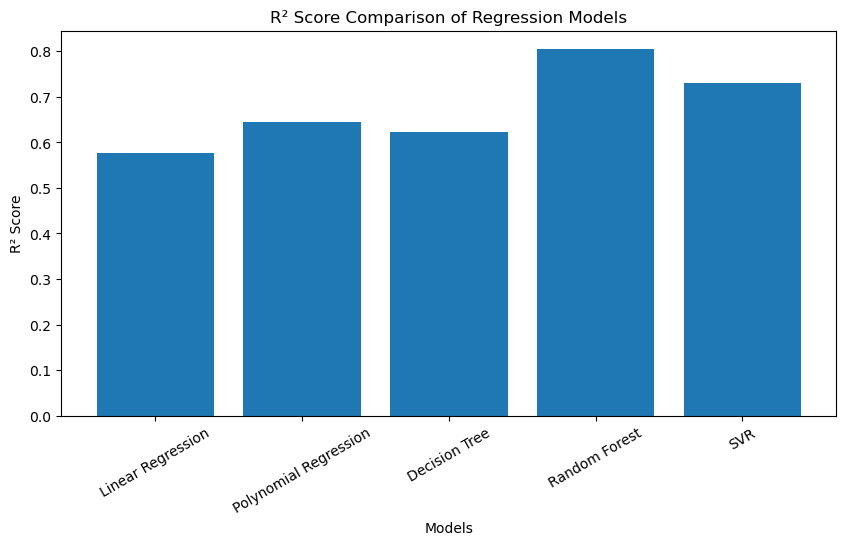

In [16]:
plt.figure(figsize=(10, 5))

plt.bar(
    results_df.index,
    results_df["R2 Score"]
)

plt.xlabel("Models")
plt.ylabel("R² Score")
plt.title("R² Score Comparison of Regression Models")

plt.xticks(rotation=30)

plt.show()